<a href="https://colab.research.google.com/github/Patrick190508/whaleshark-mafia-island/blob/main/notebooks/Model_v2_Ningaloo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model v2 — Daily whale shark encounter prediction, Ningaloo Reef
*(title and introduction to be written)*

Question: "Will today be a better-than-average day for its season?"
Data: `daily_ningaloo.csv` with wind, waves, their 3/7-day history, wind-noise index, lunar phase.

## 1. Data

### 1.1 Load the daily series and build the season table

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

URL = "https://raw.githubusercontent.com/Patrick190508/whaleshark-mafia-island/main/data/daily_ningaloo.csv"
d = pd.read_csv(URL, parse_dates=["date"])

PEAK = [4, 5, 6]                                   # Ningaloo season: April–June
d = d[d["month"].isin(PEAK)].copy()
d["sday"] = d.groupby("year").cumcount() + 1       # day of season 1..91
d["week"] = (d["sday"] - 1) // 7 + 1

# active seasons only (>= 20 sightings), as in the EDA
tot = d.groupby("year")["sightings"].sum()
active = tot[tot >= 20].index
d = d[d["year"].isin(active)].dropna(subset=["sst", "chl", "sss", "wind", "wave"]).copy()

# squared terms
d["sday2"] = d["sday"] ** 2
d["sst2"]  = d["sst"] ** 2
d["wave2"] = d["wave"] **2
d['wind2'] = d['wind'] **2

# 3-day mean wind on acoustic scale (dB)
d["noise_3d"] = 20 * np.log10(d["wind_3d"].clip(lower=0.5))

# target: better-than-average day for its own season
avg = d.groupby("year")["sightings"].transform("mean")
d["y"] = (d["sightings"] > avg).astype(int)

print("seasons:", sorted(d["year"].unique()))
print("rows:", len(d), "| good days:", d["y"].sum(), f"({d['y'].mean():.0%})")
print("columns:", list(d.columns))

seasons: [np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009)]
rows: 1092 | good days: 404 (37%)
columns: ['date', 'sst', 'chl', 'sss', 'sightings', 'doy', 'year', 'month', 'wind', 'wave', 'wind_3d', 'wind_7d', 'wave_3d', 'wave_7d', 'noise_wind', 'moon', 'moon_illum', 'sday', 'week', 'sday2', 'sst2', 'wave2', 'wind2', 'noise_3d', 'y']


### 1.2 Train / validation / test split by season

In [3]:
TRAIN = list(range(1998, 2005))
VAL   = [2005, 2006]
TEST  = [2007, 2008, 2009]

train = d[d["year"].isin(TRAIN)]
val   = d[d["year"].isin(VAL)]
test  = d[d["year"].isin(TEST)]

for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:11s} seasons {part['year'].min()}–{part['year'].max()} | "
          f"days {len(part):4d} | share of good days {part['y'].mean():.0%}")

train       seasons 1998–2004 | days  637 | share of good days 33%
validation  seasons 2005–2006 | days  182 | share of good days 43%
test        seasons 2007–2009 | days  273 | share of good days 42%


## 2. Metrics

### Why accuracy is not enough
Accuracy doesn't take into consideration the set imbalance. In our case with 63% of normal day the always-no model will have an accuracy of 63% and our best model had an accuracy of 66% in the testing set.

Than accuracy treat False positive and false negative at the same way but in the real world we may prefer a model with lower accuracy but with less false positive

### What are other metrics that we can use to analyze our model



*   Precision Score: To analyze the number of True positive (good days recognized by the model) over the real positive - TP/(TP+FP) - If Precision score is high it's an indicator of few False positives.
*   Recall Score of all better-than-avarage days: High recall = few better-than-avarage days lost
*   F1 Score: Avarage between Precision and recall scores - Usefull to check if the model is balanced between beeing precise and losing better-than-avarage days
*   ROC-AUC: a value that shows how well the model ranks the days: whether better-than-average days receive a higher probability than normal days. It does not depend on the threshold. 0.5 = random, 1 = perfect ranking.



### 2.2 Evaluation function
All metrics at one threshold, plus ROC-AUC (threshold-free).

In [4]:
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, confusion_matrix)

def evaluate(y_true, p, thr=0.5, label=""):
    """One row of metrics for a vector of probabilities p at threshold thr."""
    p = np.asarray(p, dtype=float)
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    row = {
        "model": label, "thr": thr,
        "accuracy":     accuracy_score(y_true, pred),
        "precision":    precision_score(y_true, pred, zero_division=0),
        "recall":       recall_score(y_true, pred, zero_division=0),
        "f1":           f1_score(y_true, pred, zero_division=0),
        "roc_auc":      roc_auc_score(y_true, p) if len(np.unique(p)) > 1 else 0.5,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }
    return row

def metrics_table(rows):
    """Collect rows from evaluate() into one table."""
    t = pd.DataFrame(rows).set_index("model")
    return t.round(2)

## 3. Variables — do they separate good days from normal days?

### 3.1 Class tables on the training seasons
Share of better-than-average days per class of each variable, against the overall share.

In [5]:
def class_table(col, bins, labels):
    t = train.assign(c=pd.cut(train[col], bins=bins, labels=labels))
    tab = t.groupby("c", observed=True)["y"].agg(days="size", share_good="mean").round(2)
    print(f"\n{col}   (overall share of good days: {train['y'].mean():.2f})")
    print(tab.to_string())

print(train[["wave", "wind", "noise_wind"]].describe().round(2))

WIND = ([0, 3, 5, 7, 10, 99], ["0–3", "3–5", "5–7", "7–10", ">10 m/s"])
WAVE = ([0, 0.5, 1, 1.5, 2, 99], ["<0.5", "0.5–1", "1–1.5", "1.5–2", ">2 m"])
MOON = ([-0.01, 0.25, 0.5, 0.75, 1.01], ["dark", "waxing", "bright", "waning"])

class_table("wind",     *WIND)
class_table("wind_3d",  *WIND)
class_table("wind_7d",  *WIND)
class_table("wave",     *WAVE)
class_table("wave_3d",  *WAVE)
class_table("wave_7d",  *WAVE)
class_table("moon_illum", *MOON)

         wave    wind  noise_wind
count  637.00  637.00      637.00
mean     1.84    5.26       13.90
std      0.50    1.79        3.10
min      0.68    1.61        4.16
25%      1.43    3.80       11.59
50%      1.80    5.16       14.25
75%      2.18    6.49       16.25
max      3.38   11.26       21.03

wind   (overall share of good days: 0.33)
         days  share_good
c                        
0–3        64        0.33
3–5       240        0.35
5–7       225        0.33
7–10      105        0.29
>10 m/s     3        0.00

wind_3d   (overall share of good days: 0.33)
         days  share_good
c                        
0–3        16        0.50
3–5       280        0.38
5–7       263        0.28
7–10       77        0.29
>10 m/s     1        0.00

wind_7d   (overall share of good days: 0.33)
      days  share_good
c                     
0–3      3        1.00
3–5    274        0.35
5–7    324        0.32
7–10    36        0.17

wave   (overall share of good days: 0.33)
       days  s

*Reading:* From the first analysis of the wind and moon variables we can't see any strong pattern. However the wave variable show a clearer correlation: with waves under 2 meters the shares of good days is above 0.36 while when waves are above than 2 meters the shares drops to 0.23.

### 3.2 Correlation of each variable with the target
Point-biserial correlation (= Pearson between the 0/1 target and the variable) on the training seasons, sorted.

wave         -0.13
wave_3d      -0.13
wind_3d      -0.11
wave_7d      -0.08
wind_7d      -0.08
wind         -0.07
sday         -0.07
noise_wind   -0.06
sss          -0.02
chl           0.04
sst           0.06
moon_illum    0.08
Name: y, dtype: float64


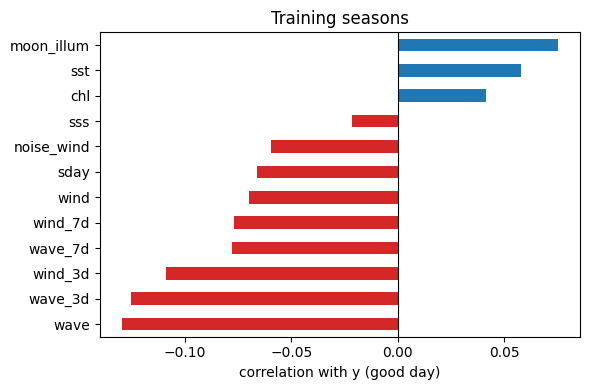

In [6]:
# 3.2 Correlation with the target (training seasons only)
VARS = ["sday", "sst", "chl", "sss",
        "wind", "wind_3d", "wind_7d", "noise_wind",
        "wave", "wave_3d", "wave_7d",
        "moon_illum"]

corr = train[VARS + ["y"]].corr()["y"].drop("y").sort_values()
print(corr.round(2))

plt.figure(figsize=(6, 4))
corr.plot.barh(color=["tab:red" if c < 0 else "tab:blue" for c in corr])
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("correlation with y (good day)")
plt.title("Training seasons")
plt.tight_layout(); plt.show()

*Reading:* All the variables have a low correlation with our output value. However the best factor is wave which confirm what we saw in the previous step

## 4. Models

### 4.1 Features and scaling
Choose `FEATS` from section 3.

In [23]:
# 4.1 Feature sets
FEATS_BASE = ["sday", "sday2", "sss", "sst", "sst2", "chl"]                                                                      # MVP (slow variables + season shape)
FEATS_FAST = ["wind", "wind_3d", "wind2", "wave", "wave2", "moon_illum", "noise_wind"]
FEATS = FEATS_BASE + FEATS_FAST

Xtr, ytr = train[FEATS], train["y"]
Xva, yva = val[FEATS],   val["y"]
Xte, yte = test[FEATS],  test["y"]

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(Xtr)
Xtr_s, Xva_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xva), scaler.transform(Xte)
print(len(FEATS), "features:", FEATS)

13 features: ['sday', 'sday2', 'sss', 'sst', 'sst2', 'chl', 'wind', 'wind_3d', 'wind2', 'wave', 'wave2', 'moon_illum', 'noise_wind']


### 4.2 Weekly baseline

In [24]:
# 4.2 Weekly baseline: share of good days per week of the season (training only)
week_share = train.groupby("week")["y"].mean()

def baseline_prob(df):
    return df["week"].map(week_share).fillna(train["y"].mean()).values

p_base_tr, p_base_va = baseline_prob(train), baseline_prob(val)

rows = [evaluate(ytr, p_base_tr, 0.5, "baseline train"),
        evaluate(yva, p_base_va, 0.5, "baseline val")]
metrics_table(rows)

,thr,accuracy,precision,recall,f1,roc_auc,TP,FP,FN,TN
model,,,,,,,,,,
baseline train,0.5,0.67,0.0,0.0,0.0,0.63,0,0,210,427
baseline val,0.5,0.57,0.0,0.0,0.0,0.61,0,0,79,103


### 4.3 Logistic regression (linear) and with squared terms

In [25]:
# 4.3 Logistic regression (with squared terms sday2, sst2 already in FEATS)
from sklearn.linear_model import LogisticRegression

logit = LogisticRegression(max_iter=1000).fit(Xtr_s, ytr)
p_log_tr, p_log_va = logit.predict_proba(Xtr_s)[:, 1], logit.predict_proba(Xva_s)[:, 1]

rows = [evaluate(ytr, p_log_tr, 0.5, "logistic train"),
        evaluate(yva, p_log_va, 0.5, "logistic val")]
metrics_table(rows)

,thr,accuracy,precision,recall,f1,roc_auc,TP,FP,FN,TN
model,,,,,,,,,,
logistic train,0.5,0.67,0.50,0.12,0.19,0.67,25,25,185,402
logistic val,0.5,0.62,0.75,0.19,0.30,0.71,15,5,64,98


### 4.4 Small neural network (Week 6)

In [ ]:
# 4.4 Neural network grid: depth 1..10 x width 8..32 (same width in every layer)
import tensorflow as tf, time
tf.random.set_seed(0); np.random.seed(0)

DEPTHS = range(1, 11)
WIDTHS = [8, 12, 16, 20, 24, 28, 32]

def make_nn(depth, width, dropout=0.2):
    m = tf.keras.Sequential([tf.keras.layers.Input(shape=(Xtr_s.shape[1],))])
    for _ in range(depth):
        m.add(tf.keras.layers.Dense(width, activation="relu"))
        m.add(tf.keras.layers.Dropout(dropout))
    m.add(tf.keras.layers.Dense(1, activation="sigmoid"))
    m.compile(optimizer="adam", loss="binary_crossentropy")
    return m

stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)

grid, nn_probs, t0 = [], {}, time.time()
for depth in DEPTHS:
    for width in WIDTHS:
        tf.keras.backend.clear_session(); tf.random.set_seed(0)
        nn = make_nn(depth, width)
        nn.fit(Xtr_s, ytr, validation_data=(Xva_s, yva),
               epochs=300, batch_size=32, callbacks=[stop], verbose=0)
        p_tr, p_va = nn.predict(Xtr_s, verbose=0).ravel(), nn.predict(Xva_s, verbose=0).ravel()
        name = f"nn_d{depth}_w{width}"
        nn_probs[name] = (nn, p_tr, p_va)
        grid.append({"depth": depth, "width": width,
                     "auc_train": roc_auc_score(ytr, p_tr), "auc_val": roc_auc_score(yva, p_va),
                     "epochs": len(nn.history.history["loss"])})
        print(f"{name}: val AUC {grid[-1]['auc_val']:.3f}  ({time.time()-t0:.0f}s)")

grid = pd.DataFrame(grid)
auc_table = grid.pivot(index="depth", columns="width", values="auc_val").round(3)
print("\nROC-AUC on validation (rows = depth, columns = width)")
display(auc_table)

best = grid.loc[grid["auc_val"].idxmax()]
BEST_NN = f"nn_d{int(best.depth)}_w{int(best.width)}"
print(f"\nbest: {BEST_NN}  val AUC {best.auc_val:.3f}  train AUC {best.auc_train:.3f}")

nn_d1_w8: val AUC 0.703  (38s)
nn_d1_w12: val AUC 0.567  (43s)
nn_d1_w16: val AUC 0.587  (47s)
nn_d1_w20: val AUC 0.502  (50s)
nn_d1_w24: val AUC 0.570  (55s)
nn_d1_w28: val AUC 0.539  (59s)
nn_d1_w32: val AUC 0.479  (63s)
nn_d2_w8: val AUC 0.618  (68s)
nn_d2_w12: val AUC 0.563  (72s)
nn_d2_w16: val AUC 0.572  (77s)
nn_d2_w20: val AUC 0.639  (81s)
nn_d2_w24: val AUC 0.418  (86s)
nn_d2_w28: val AUC 0.520  (90s)
nn_d2_w32: val AUC 0.522  (95s)
nn_d3_w8: val AUC 0.455  (99s)
nn_d3_w12: val AUC 0.494  (105s)
nn_d3_w16: val AUC 0.520  (110s)
nn_d3_w20: val AUC 0.616  (118s)
nn_d3_w24: val AUC 0.549  (122s)
nn_d3_w28: val AUC 0.616  (127s)
nn_d3_w32: val AUC 0.715  (138s)
nn_d4_w8: val AUC 0.547  (144s)
nn_d4_w12: val AUC 0.562  (149s)
nn_d4_w16: val AUC 0.535  (155s)
nn_d4_w20: val AUC 0.482  (160s)
nn_d4_w24: val AUC 0.553  (165s)
nn_d4_w28: val AUC 0.489  (171s)
nn_d4_w32: val AUC 0.595  (176s)
nn_d5_w8: val AUC 0.527  (182s)
nn_d5_w12: val AUC 0.452  (189s)
nn_d5_w16: val AUC 0.601  (196

width,8,12,16,20,24,28,32
depth,,,,,,,
1,0.703,0.567,0.587,0.502,0.570,0.539,0.479
2,0.618,0.563,0.572,0.639,0.418,0.520,0.522
3,0.455,0.494,0.520,0.616,0.549,0.616,0.715
4,0.547,0.562,0.535,0.482,0.553,0.489,0.595
5,0.527,0.452,0.601,0.477,0.545,0.649,0.449
6,0.563,0.367,0.628,0.528,0.544,0.589,0.575
7,0.439,0.564,0.637,0.489,0.625,0.555,0.621
8,0.440,0.633,0.633,0.484,0.593,0.581,0.507
9,0.511,0.617,0.527,0.573,0.535,0.591,0.561



best: nn_d3_w32  val AUC 0.715  train AUC 0.762


From the first analysis we can't see any relationship between the structure of the neural networks and how well they perform since values range from 0.37 to 0.72 with no order. After some research I found out that this is a sign of the neural networks not having enough data to train on, so they can't learn a stable pattern with the current amount of data we have. To check this i change the seed of the neural networks and see how much it varies between seeds.

In [ ]:
# 4.4b Stability check: same architecture, different random seeds
CHECK = [(1, 8), (3, 32), (2, 20)]
SEEDS = [0, 1, 2, 3, 4]
rows = []
for depth, width in CHECK:
    aucs = []
    for s in SEEDS:
        tf.keras.backend.clear_session(); tf.random.set_seed(s); np.random.seed(s)
        nn = make_nn(depth, width)
        nn.fit(Xtr_s, ytr, validation_data=(Xva_s, yva),
               epochs=300, batch_size=32, callbacks=[stop], verbose=0)
        aucs.append(roc_auc_score(yva, nn.predict(Xva_s, verbose=0).ravel()))
    rows.append({"net": f"d{depth}_w{width}", "mean": np.mean(aucs), "std": np.std(aucs),
                 "min": np.min(aucs), "max": np.max(aucs)})
print("logistic val AUC:", round(roc_auc_score(yva, p_log_va), 3))
pd.DataFrame(rows).set_index("net").round(3)

NameError: name 'tf' is not defined

From the output we can see that the neural networks can't do better than the logistic and they are also unstable (for d3_w32 minimum at 0.503 and maximum at 0.671). This confirms that neural networks performed well in the good cases because of luck: if the networks had learned a real pattern, the seed would not change the result.

From here on we will use the logistic regression models and I will mark the NN as a negative result due to lack of data

### 4.5 Metrics on the validation set — all models, several thresholds
ROC-AUC to compare models; precision / recall to choose the threshold.

In [26]:
# 4.5 Threshold choice for the logistic model (validation set)
rows = [evaluate(yva, p_log_va, t, f"logistic thr {t}") for t in [0.3, 0.35, 0.4, 0.45, 0.5]]
rows.append(evaluate(yva, p_base_va, 0.3, "baseline thr 0.3"))
print("reference: always 'good' -> precision", round(yva.mean(), 2), "| always 'no' -> accuracy", round(1 - yva.mean(), 2))
metrics_table(rows)

reference: always 'good' -> precision 0.43 | always 'no' -> accuracy 0.57


,thr,accuracy,precision,recall,f1,roc_auc,TP,FP,FN,TN
model,,,,,,,,,,
logistic thr 0.3,0.30,0.63,0.55,0.81,0.66,0.71,64,52,15,51
logistic thr 0.35,0.35,0.68,0.62,0.66,0.64,0.71,52,32,27,71
logistic thr 0.4,0.40,0.68,0.66,0.52,0.58,0.71,41,21,38,82
logistic thr 0.45,0.45,0.61,0.59,0.34,0.43,0.71,27,19,52,84
logistic thr 0.5,0.50,0.62,0.75,0.19,0.30,0.71,15,5,64,98
baseline thr 0.3,0.30,0.58,0.51,0.72,0.60,0.61,57,55,22,48


Reading: From the analysis of the accuracy score we can see that the best choice is the logistic with threshold at 0.35. However if we prefer to minimise the number of better than avarage days missed (false negatives) then the logistic regression with threshold at 0.3 is the better choice. This is a perfect example of how two different metrics can give different answers to a single question.

### 4.6 Which variables does the model use? Coefficients, and whether their sign is stable between training and validation

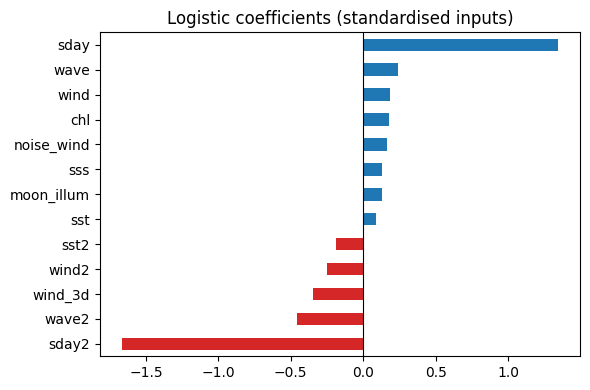

,no 1998,no 1999,no 2000,no 2001,no 2002,no 2003,no 2004,same sign
sday,1.42,1.04,1.44,1.36,1.39,1.31,1.22,True
sday2,-1.34,-1.27,-1.85,-1.65,-1.98,-1.55,-1.63,True
sss,0.33,0.29,0.06,0.01,0.16,0.09,0.05,True
sst,0.34,0.14,-0.13,0.03,0.03,0.14,0.13,False
sst2,0.13,-0.13,-0.24,-0.26,-0.18,-0.17,-0.32,False
chl,0.21,0.21,0.14,0.18,0.18,0.18,0.10,True
wind,0.26,0.14,0.23,0.14,0.12,0.26,0.22,True
wind_3d,-0.31,-0.34,-0.31,-0.42,-0.24,-0.40,-0.32,True
wind2,-0.30,-0.29,-0.06,-0.38,-0.18,-0.21,-0.31,True
wave,0.26,0.20,0.10,0.31,0.09,0.18,0.30,True


In [27]:
# 4.6 Coefficients and sign stability
THR = 0.30

# a) coefficients of the final logistic model (inputs are standardised, so sizes are comparable)
coef = pd.Series(logit.coef_[0], index=FEATS).sort_values()
plt.figure(figsize=(6, 4))
coef.plot.barh(color=["tab:red" if c < 0 else "tab:blue" for c in coef])
plt.axvline(0, color="k", lw=0.8)
plt.title("Logistic coefficients (standardised inputs)")
plt.tight_layout(); plt.show()

# b) leave-one-season-out: refit without each training season, does every coefficient keep its sign?
signs = {}
for yr in sorted(train["year"].unique()):
    sub = train[train["year"] != yr]
    m = LogisticRegression(max_iter=1000).fit(scaler.transform(sub[FEATS]), sub["y"])
    signs[f"no {yr}"] = pd.Series(m.coef_[0], index=FEATS)
signs = pd.DataFrame(signs)
signs["same sign"] = (np.sign(signs).nunique(axis=1) == 1)
signs.round(2)

*Reading:*

## 5. Test (used once)

In [13]:
# 5. Test on unseen seasons (2007-2009), run once with the threshold fixed on validation
THR = 0.3

p_log_te  = logit.predict_proba(Xte_s)[:, 1]
p_base_te = baseline_prob(test)

rows = [evaluate(yte, p_base_te, THR, "baseline (test)"),
        evaluate(yte, p_log_te,  THR, "logistic (test)"),
        evaluate(yva, p_log_va,  THR, "logistic (val, for comparison)")]
print("test reference: always 'good' -> precision", round(yte.mean(), 2),
      "| always 'no' -> accuracy", round(1 - yte.mean(), 2))
metrics_table(rows)

test reference: always 'good' -> precision 0.42 | always 'no' -> accuracy 0.58


,thr,accuracy,precision,recall,f1,roc_auc,TP,FP,FN,TN
model,,,,,,,,,,
baseline (test),0.3,0.54,0.47,0.69,0.56,0.57,79,89,36,69
logistic (test),0.3,0.61,0.53,0.75,0.62,0.64,86,77,29,81
"logistic (val, for comparison)",0.3,0.63,0.55,0.80,0.65,0.71,63,52,16,51


In [14]:
# 5b. Test, season by season
rows = []
for yr in sorted(test["year"].unique()):
    mask = (test["year"] == yr).values
    rows.append(evaluate(yte[mask], p_log_te[mask], THR, f"logistic {yr}"))
    rows.append(evaluate(yte[mask], p_base_te[mask], THR, f"baseline {yr}"))
metrics_table(rows)

,thr,accuracy,precision,recall,f1,roc_auc,TP,FP,FN,TN
model,,,,,,,,,,
logistic 2007,0.3,0.51,0.43,0.65,0.52,0.52,24,32,13,22
baseline 2007,0.3,0.48,0.41,0.62,0.49,0.48,23,33,14,21
logistic 2008,0.3,0.68,0.57,0.75,0.65,0.70,27,20,9,35
baseline 2008,0.3,0.56,0.46,0.72,0.57,0.62,26,30,10,25
logistic 2009,0.3,0.65,0.58,0.83,0.69,0.69,35,25,7,24
baseline 2009,0.3,0.58,0.54,0.71,0.61,0.61,30,26,12,23


*Reading:* From the testing set the result are positive. On two of three unseen seasons the model is near the validation level (2008,2009); on 2007 neither the model nor the seasonal baseline work, which can suggest a specific factor exclusive to this year.

## 6. Other sites — same pipeline, then transfer
Two questions, in this order:
1. **Same model, site by site.** Does the pipeline built on Ningaloo (season table, better-than-average target, split by season, logistic regression with squared terms, threshold 0.3) also work at Donsol (Philippines) and Tofo (Mozambique)? Do wind and waves keep the same sign?
2. **Transfer.** A model trained on one site, applied to the days of another site without retraining. Does a rule learned in one place hold in another?

Seasons: Ningaloo April–June, Philippines February–May, Mozambique October–February (the April peak seen in the EDA is left out, as in the EDA). A season that crosses New Year (Mozambique) is labelled with the year in which it starts.

### 6.1 One function for the whole pipeline
`build_site` repeats cells 1.1 and 1.2 for any site; `fit_site` repeats 4.1–4.3. Split rule: the last 3 active seasons are the test, the 2 before are validation, the rest training.

In [16]:
# 6.1 Pipeline as functions (same steps as sections 1 and 4)
BASE = "https://raw.githubusercontent.com/Patrick190508/whaleshark-mafia-island/main/data/"
SITES = {"ningaloo": [4, 5, 6], "philippines": [2, 3, 4, 5], "mozambique": [10, 11, 12, 1, 2]}

def build_site(tag, peak):
    s = pd.read_csv(BASE + f"daily_{tag}.csv", parse_dates=["date"])
    s = s[s["month"].isin(peak)].copy()
    # season label: if the season crosses New Year, months before the first peak month belong to the previous year
    wraps = peak[0] > peak[-1]
    s["season"] = np.where(wraps & (s["month"] < peak[0]), s["year"] - 1, s["year"])
    s = s.sort_values("date")
    s["sday"] = s.groupby("season").cumcount() + 1
    s["week"] = (s["sday"] - 1) // 7 + 1
    tot = s.groupby("season")["sightings"].sum()
    s = s[s["season"].isin(tot[tot >= 20].index)]
    s = s.dropna(subset=["sst", "chl", "sss", "wind", "wave"]).copy()
    for c in ["sday", "sst", "wave", "wind"]:
        s[c + "2"] = s[c] ** 2
    avg = s.groupby("season")["sightings"].transform("mean")
    s["y"] = (s["sightings"] > avg).astype(int)
    seasons = sorted(s["season"].unique())
    n = len(seasons)
    print(f"\n{tag:12s} sightings per active season:", tot[tot >= 20].astype(int).to_dict())
    if n >= 8:   k_te, k_va = 3, 2
    elif n >= 5: k_te, k_va = 2, 1
    else:
        print(f"{tag}: only {n} active seasons, not enough for train/val/test"); return None
    parts = {"train": seasons[:n-k_te-k_va], "val": seasons[n-k_te-k_va:n-k_te], "test": seasons[n-k_te:]}
    print(f"{tag:12s} {n} seasons | days {len(s)} | good {s['y'].mean():.0%} | "
          f"train {parts['train']}, val {parts['val']}, test {parts['test']}")
    return {k: s[s["season"].isin(v)] for k, v in parts.items()}

def fit_site(parts):
    tr = parts["train"]
    sc = StandardScaler().fit(tr[FEATS])
    m = LogisticRegression(max_iter=1000).fit(sc.transform(tr[FEATS]), tr["y"])
    wk = tr.groupby("week")["y"].mean()
    return {"scaler": sc, "model": m, "week_share": wk, "p0": tr["y"].mean()}

def predict_site(fit, df, scaler=None):
    sc = scaler if scaler is not None else fit["scaler"]
    return fit["model"].predict_proba(sc.transform(df[FEATS]))[:, 1]

def baseline_site(fit, df):
    return df["week"].map(fit["week_share"]).fillna(fit["p0"]).values

data = {tag: build_site(tag, peak) for tag, peak in SITES.items()}
fits = {tag: fit_site(parts) for tag, parts in data.items()}


ningaloo     sightings per active season: {1995: 23, 1996: 56, 1997: 35, 1998: 35, 1999: 125, 2000: 48, 2001: 114, 2002: 211, 2003: 259, 2004: 245, 2005: 383, 2006: 252, 2007: 299, 2008: 546, 2009: 833}
ningaloo     12 seasons | days 1092 | good 37% | train [np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004)], val [np.int64(2005), np.int64(2006)], test [np.int64(2007), np.int64(2008), np.int64(2009)]

philippines  sightings per active season: {2006: 155, 2007: 218, 2008: 597, 2009: 739, 2010: 130}
philippines  5 seasons | days 601 | good 31% | train [np.int64(2006), np.int64(2007)], val [np.int64(2008)], test [np.int64(2009), np.int64(2010)]

mozambique   sightings per active season: {2005: 229, 2006: 128, 2007: 55, 2008: 157, 2009: 23}
mozambique   5 seasons | days 746 | good 23% | train [np.int64(2005), np.int64(2006)], val [np.int64(2007)], test [np.int64(2008), np.int64(2009)]


### 6.2 Same model, site by site
Test seasons of each site, threshold 0.3. Reference per site: always "good" → precision = share of good days.

In [20]:
# 6.2 One model per site: threshold chosen on each site's own validation, then test once
THRS = [0.3, 0.35, 0.4, 0.45, 0.5]
thr_site, rows_val, rows_test = {}, [], []
for tag, parts in data.items():
    va, te = parts["val"], parts["test"]
    p_va = predict_site(fits[tag], va)
    sweep = pd.DataFrame([evaluate(va["y"], p_va, t, f"{tag} thr {t}") for t in THRS]).set_index("model")
    best_t = sweep["f1"].idxmax()                       # best F1 on validation
    thr_site[tag] = float(best_t.split()[-1])
    rows_val.append(sweep.loc[best_t].rename(f"{tag} val (thr {thr_site[tag]})"))
    p_te = predict_site(fits[tag], te)
    rows_test.append(evaluate(te["y"], baseline_site(fits[tag], te), thr_site[tag], f"{tag} baseline test"))
    rows_test.append(evaluate(te["y"], p_te, thr_site[tag], f"{tag} logistic test"))
    print(f"{tag:12s} val good {va['y'].mean():.0%} | test good {te['y'].mean():.0%} | threshold {thr_site[tag]}")

print("\nvalidation, at the chosen threshold"); display(pd.DataFrame(rows_val).round(2))
print("\ntest, at the chosen threshold"); metrics_table(rows_test)

ningaloo     val good 43% | test good 42% | threshold 0.3
philippines  val good 42% | test good 32% | threshold 0.35
mozambique   val good 17% | test good 14% | threshold 0.45

validation, at the chosen threshold


,thr,accuracy,precision,recall,f1,roc_auc,TP,FP,FN,TN
ningaloo val (thr 0.3),0.30,0.63,0.55,0.80,0.65,0.71,63.0,52.0,16.0,51.0
philippines val (thr 0.35),0.35,0.79,0.78,0.71,0.74,0.81,36.0,10.0,15.0,60.0
mozambique val (thr 0.45),0.45,0.67,0.26,0.50,0.34,0.56,13.0,37.0,13.0,89.0



test, at the chosen threshold


,thr,accuracy,precision,recall,f1,roc_auc,TP,FP,FN,TN
model,,,,,,,,,,
ningaloo baseline test,0.30,0.54,0.47,0.69,0.56,0.57,79,89,36,69
ningaloo logistic test,0.30,0.61,0.53,0.75,0.62,0.64,86,77,29,81
philippines baseline test,0.35,0.57,0.31,0.28,0.30,0.44,22,48,56,114
philippines logistic test,0.35,0.66,0.47,0.40,0.43,0.52,31,35,47,127
mozambique baseline test,0.45,0.73,0.16,0.21,0.18,0.51,9,47,34,212
mozambique logistic test,0.45,0.63,0.20,0.53,0.29,0.60,23,92,20,167


From this output we can see that the logistic regression behaves differently at each site; in the Philippines we see that the validation results are excellent (AUC = 0.81, F1 = 0.74) but on the test set the results are poor (AUC = 0.52, F1 = 0.43). This is overfitting to the training seasons: with only two seasons to learn from, the model learned what 2006–07 looked like, and 2009–10 are different.

In Mozambique the results are different; in the validation set the results are poor (AUC = 0.56, F1 = 0.34) and we can see the same results in the testing set with (AUC = 0.60, F1 = 0.29). The model does slightly better than the reference but not enough to be useful

In [21]:
# 6.2b Coefficients side by side: does each variable keep its sign across sites?
coefs = pd.DataFrame({tag: pd.Series(f["model"].coef_[0], index=FEATS) for tag, f in fits.items()})
coefs["same sign"] = (np.sign(coefs).nunique(axis=1) == 1)
coefs.round(2)

,ningaloo,philippines,mozambique,same sign
sday,1.34,1.87,0.66,True
sday2,-1.66,-1.98,-0.33,True
sss,0.13,-0.05,0.32,False
sst,0.08,0.43,-0.15,False
sst2,-0.18,0.02,-0.43,False
chl,0.18,-0.58,-0.28,False
wind,0.47,0.92,0.14,True
wind_3d,-0.34,0.11,-0.06,False
wind2,-0.37,-0.82,-0.82,True
wave,0.22,-0.18,-0.05,False


From these results we can see that the day variables are always among the strongest indicator for each site. The second shared result is the squared terms of wind and waves, which are negative at all three sites. However we see lot of variation in the correlation of otheer environmental variables, according to the scientific literature. It needs to be kept in consideration that The Philippines and Mozambique models are trained on two seasons only, so a sign that differs between sites may just be noise; the signs that agree across all three are the reliable ones.

### 6.3 Transfer between sites
Model trained on site A (rows), applied to the test seasons of site B (columns), **without retraining**.
Inputs are standardised with the scaler of the *target* site, so "high wind" means high for that site; `sday` is relative to each site's own season, so day 20 of the season has the same meaning everywhere.
Diagonal = within-site result (same as 6.2). Off-diagonal = transfer.

In [22]:
# 6.3 Transfer matrix: ROC-AUC (threshold-free) and recall at THR
auc = pd.DataFrame(index=SITES, columns=SITES, dtype=float)
rec = auc.copy()
for a in SITES:                      # model trained on a
    for b in SITES:                  # applied to test seasons of b
        te = data[b]["test"]
        p = predict_site(fits[a], te, scaler=fits[b]["scaler"])
        r = evaluate(te["y"], p, THR)
        auc.loc[a, b], rec.loc[a, b] = r["roc_auc"], r["recall"]
print("ROC-AUC  (rows = trained on, columns = tested on)")
display(auc.round(2))
print("Recall at threshold", THR)
display(rec.round(2))
print("\nbaseline ROC-AUC per site:", {b: round(evaluate(data[b]['test']['y'], baseline_site(fits[b], data[b]['test']), THR)['roc_auc'], 2) for b in SITES})

ROC-AUC  (rows = trained on, columns = tested on)


,ningaloo,philippines,mozambique
ningaloo,0.64,0.62,0.48
philippines,0.60,0.52,0.52
mozambique,0.56,0.41,0.60


Recall at threshold 0.3


,ningaloo,philippines,mozambique
ningaloo,0.75,0.81,0.67
philippines,0.55,0.46,0.37
mozambique,0.62,0.65,0.77



baseline ROC-AUC per site: {'ningaloo': np.float64(0.57), 'philippines': np.float64(0.44), 'mozambique': np.float64(0.51)}


The model transfer between Ningaloo and the Philippines in both directions with an AUC for the Ningaloo-trained model on the Philippines higher than the locally trained model AUC = 0.62, AUC local = 0.52.

Mozambique is a different case and the other models doesen't perform better than the locally trained one.

## 7. Conclusions
From this second MVP we found that:


*   On Ningaloo the model beats the weekly baseline on unseen seasons (test AUC 0.64 vs 0.57, precision 0.53 vs 0.42 for “always good”) in two of three seasons; in 2007 neither works.
*   The Neural Networks are not an option for our case since we don't have enough data to train a NN without overfitting the model.
*   Logistic regression is the best model we can use for the data we have now
*   Among the fast changing variables, waves and the 3-day wind history are the useful ones.
*   The wind-driven noise proxy gives the same result as wind itself; the shipping component is missing because no daily traffic data exists before 2010.
*   A local model needs more than two training seasons. The Ningaloo model transfers to the Philippines (AUC 0.62, better than the local 0.52) and back; Mozambique does not transfer either way.
